<a href="https://colab.research.google.com/github/reitezuz/18NES2-2026/blob/main/week08/coco_object_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Object detection on the COCO dataset

Based on:
- [Deep Learning with Python – Chapter 12: Object detection](https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter12_object-detection.ipynb)

In this notebook, we will explore object detection: identifying objects in an image and locating each object with a bounding box.

1. We will first build and train a custom detector inspired by the original YOLO architecture (2015) from scratch on the COCO dataset, which provides images annotated with object categories and bounding boxes.

2. We will then use a pretrained RetinaNet model to detect objects in new images without training the model ourselves.

Dataset:
- [COCO – dataset overview](https://cocodataset.org/#home)
- [COCO – download page and annotations](https://cocodataset.org/#download)
- [COCO 2017 – training images (ZIP)](http://images.cocodataset.org/zips/train2017.zip)

In [ ]:
#!pip install keras keras-hub --upgrade -q

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "jax"

In [ ]:
# @title
import os
from IPython.core.magic import register_cell_magic

@register_cell_magic
def backend(line, cell):
    current, required = os.environ.get("KERAS_BACKEND", ""), line.split()[-1]
    if current == required:
        get_ipython().run_cell(cell)
    else:
        print(f"This cell requires the {required} backend. To run it, change KERAS_BACKEND to \"{required}\" at the top of the notebook, restart the runtime, and rerun the notebook.")

In [ ]:
import jax
print(jax.devices())

[CudaDevice(id=0)]


## Train a YOLO model from scratch

### Download the COCO dataset

In [ ]:
import keras
import keras_hub

images_path = keras.utils.get_file("coco", "http://images.cocodataset.org/zips/train2017.zip",extract=True,)
annotations_path = keras.utils.get_file("annotations", "http://images.cocodataset.org/annotations/annotations_trainval2017.zip", extract=True, )

print("images_path =", repr(images_path))
print("annotations_path =", repr(annotations_path))

/home/zuzka/test_tf/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


images_path = '/home/zuzka/.keras/datasets/coco'
annotations_path = '/home/zuzka/.keras/datasets/annotations'


### Parse COCO annotations

We will load the bounding boxes and class labels and group them by image. COCO stores each bounding box as `[x, y, width, height]`, where `(x, y)` is its top-left corner.

We will then normalize the coordinates to the range `[0, 1]`, accounting for the padding used to center each image in a square.

In [ ]:
import json

# Load the COCO training annotations
with open(f"{annotations_path}/annotations/instances_train2017.json", "r") as f:
    annotations = json.load(f)

# Index image metadata by image ID for quick lookup
images = {image["id"]: image for image in annotations["images"]}


def scale_box(box, width, height):
    # Normalize coordinates by the longer image dimension
    scale = 1.0 / max(width, height)
    x, y, w, h = [v * scale for v in box]

    # Shift the box to account for padding when centering the image in a square
    x += (height - width) * scale / 2 if height > width else 0
    y += (width - height) * scale / 2 if width > height else 0

    return [x, y, w, h]


# Group bounding boxes and class labels by image ID
metadata = {}
for annotation in annotations["annotations"]:
    image_id = annotation["image_id"]
    if image_id not in metadata:
        metadata[image_id] = {"boxes": [], "labels": []}

    # Look up the image dimensions and normalize the bounding box
    image = images[image_id]
    box = scale_box(annotation["bbox"], image["width"], image["height"])

    # Store the box, its class label, and the image path
    metadata[image_id]["boxes"].append(box)
    metadata[image_id]["labels"].append(annotation["category_id"])
    metadata[image_id]["path"] = images_path + "/train2017/" + image["file_name"]

# Convert the dictionary to a list with one entry per annotated image
metadata = list(metadata.values())

### Observe the data

In [ ]:
len(metadata)  # number of images in the dataset

117266

In [ ]:
min([len(x["boxes"]) for x in metadata])  # minimum number of objects in an image

1

In [ ]:
max([len(x["boxes"]) for x in metadata]) # maximum number of objects in an image

93

Maximum number of objects in an image: 93


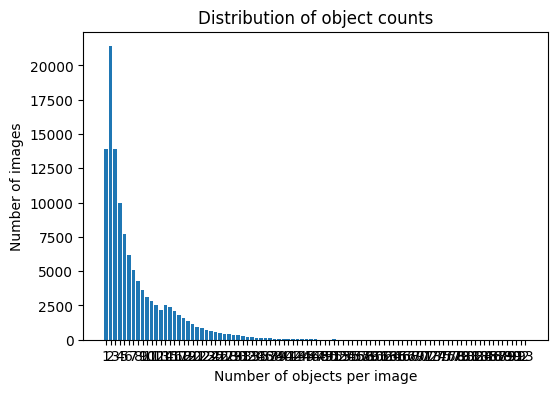

In [ ]:
# Distribution of object counts

# Count the annotated objects in each image
import matplotlib.pyplot as plt

# Count the annotated objects in each image
object_counts = [len(sample["boxes"]) for sample in metadata]
print("Maximum number of objects in an image:", max(object_counts))

# Plot the distribution of object counts
plt.figure(figsize=(6, 4))
plt.hist(
    object_counts,
    bins=range(min(object_counts), max(object_counts) + 2),
    align="left",
    rwidth=0.8,
)
plt.xticks(range(min(object_counts), max(object_counts) + 1))
plt.xlabel("Number of objects per image")
plt.ylabel("Number of images")
plt.title("Distribution of object counts")
plt.show()

In [ ]:
max(max(x["labels"]) for x in metadata) + 1 # number of possible labels

91

In [ ]:
metadata[315] # bounding boxes for an image

{'boxes': [[0.26709375, 0.651515625, 0.1433125, 0.28140625],
  [0.40459375, 0.112265625, 0.34871875, 0.2185625],
  [0.500296875, 0.003328125, 0.181796875, 0.246890625],
  [0.179578125, 0.05565625, 0.1985625, 0.11640625]],
 'labels': [16, 2, 1, 15],
 'path': '/home/zuzka/.keras/datasets/coco/train2017/000000019608.jpg'}

In [ ]:
[keras_hub.utils.coco_id_to_name(x) for x in metadata[315]["labels"]] # map labels to names

['bird', 'bicycle', 'person', 'bench']

### Visualize images and bounding boxes

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from matplotlib.patches import Rectangle

# Store a color for each class label
color_map = {0: "gray"}

def label_to_color(label):
    # Assign a color to each new label and reuse it on subsequent calls
    if label not in color_map:
        # Space hues around the color wheel using the golden ratio
        h, s, v = (len(color_map) * 0.618) % 1, 0.5, 0.9
        color_map[label] = hsv_to_rgb((h, s, v))
    return color_map[label]


def draw_box(ax, box, text, color):
    # Draw a bounding box in normalized [x, y, width, height] format
    x, y, w, h = box
    ax.add_patch(Rectangle((x, y), w, h, lw=2, ec=color, fc="none"))

    # Place the label above the top-left corner on a colored background
    textbox = dict(fc=color, pad=1, ec="none")
    ax.text(x, y, text, c="white", size=10, va="bottom", bbox=textbox)


def draw_image(ax, image):
    # Use a unit square with the origin at the top-left corner
    ax.set(xlim=(0, 1), ylim=(1, 0), xticks=[], yticks=[], aspect="equal")

    # Load the image and get its original dimensions
    image = plt.imread(image)
    height, width = image.shape[:2]

    # Compute margins to center the image while preserving its aspect ratio
    hpad = (1 - height / width) / 2 if width > height else 0
    wpad = (1 - width / height) / 2 if height > width else 0

    # Display the image in the same coordinate system as the scaled boxes
    extent = [wpad, 1 - wpad, 1 - hpad, hpad]
    ax.imshow(image, extent=extent)

def show_sample(i):
    # Select an image and its annotations
    sample = metadata[i]

    fig, ax = plt.subplots(dpi=200)
    draw_image(ax, sample["path"])

    # Draw each bounding box with its class name and color
    for box, label in zip(sample["boxes"], sample["labels"]):
        label_name = keras_hub.utils.coco_id_to_name(label)
        draw_box(ax, box, label_name, label_to_color(label))

    plt.show()


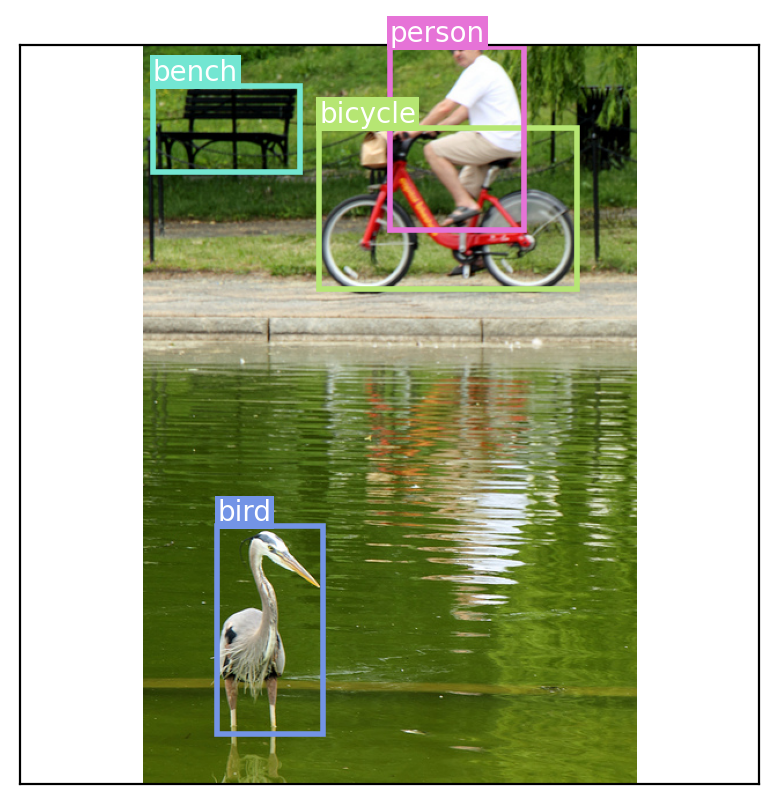

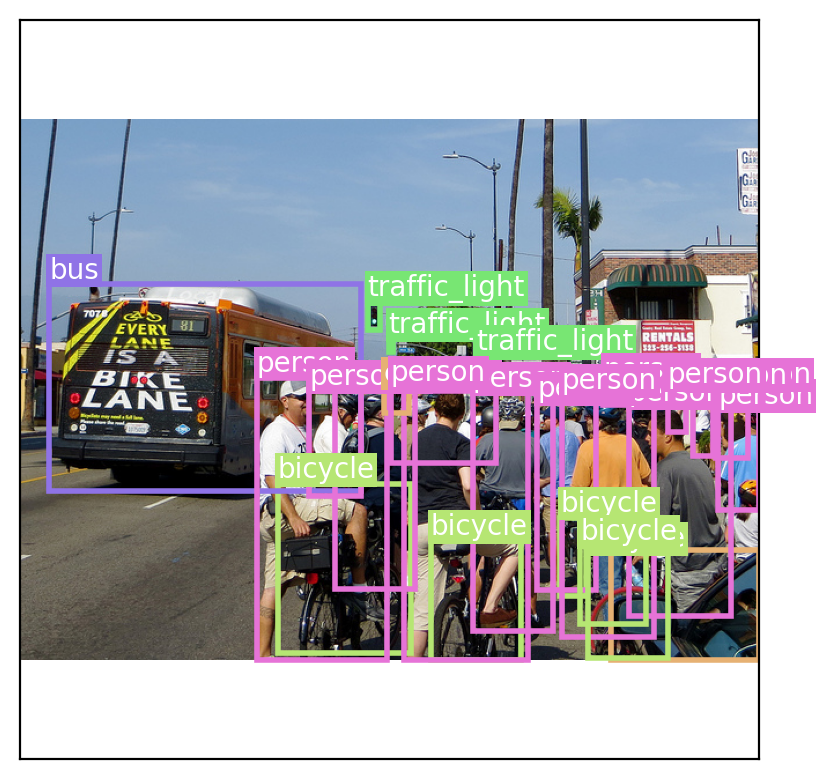

In [ ]:
#show_sample(435)  # Set image index
show_sample(315)  # Set image index
show_sample(1215)  # Set image index

### Make the dataset smaller

In [ ]:
import random

# Keep only images with at most 4 annotated objects
num_objects = 4
metadata = [sample for sample in metadata if len(sample["boxes"]) <= num_objects]

# Shuffle the filtered dataset
random.shuffle(metadata)

# Display the number of remaining images
len(metadata)

59203

## Create a YOLO model

### Preparing the ResNet backbone and image preprocessing
Load a ResNet-50 backbone pretrained on ImageNet and its matching image converter, configured to resize images to 448 × 448 pixels.

In [ ]:
image_size = 448

backbone = keras_hub.models.Backbone.from_preset("resnet_50_imagenet")
preprocessor = keras_hub.layers.ImageConverter.from_preset(
    "resnet_50_imagenet",
    image_size=(image_size, image_size),
)

### Building a YOLO-style detection model

We will add a detection head to the ResNet backbone. For each cell in a 6 × 6 grid, the model will predict one bounding box, an objectness score, and class probabilities.

#### How the model works

- The **ResNet backbone** extracts a spatial feature map from the input image.
- The detection head processes these features and produces predictions arranged in a **6 × 6 grid**.
- Each grid cell predicts **one bounding box**, an **objectness score**, and **class probabilities**. A cell is responsible for an object whose center falls inside it, but the predicted box may extend beyond the cell.

For each cell, the model outputs **96 values**:
- **4 values:** bounding box coordinates and size.
- **1 value:** objectness score.
- **91 values:** class probabilities.

The `box` and `class` outputs are two parts of the same prediction: the box and class at a given grid position belong together.

The model produces **36 candidate boxes** per image. During inference, low-confidence predictions are filtered out, and non-maximum suppression (NMS) can remove duplicate detections.

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 448, 448,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res_net_backbone    │ (None, 14, 14,    │ 23,561,152 │ input_layer_1[0]… │
│ (ResNetBackbone)    │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 6, 6, 512) │  9,437,696 │ res_net_backbone… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 18432)     │          0 │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 2048)      │ 37,750,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3456)      │  7,081,344 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 6, 6, 96)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 6, 6, 91)  │          0 │ reshape[0][0]     │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 6, 6, 5)   │          0 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 6, 6, 91)  │          0 │ get_item_1[0][0]  │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 77,830,976 (296.90 MB)

 Trainable params: 77,777,856 (296.70 MB)

 Non-trainable params: 53,120 (207.50 KB)

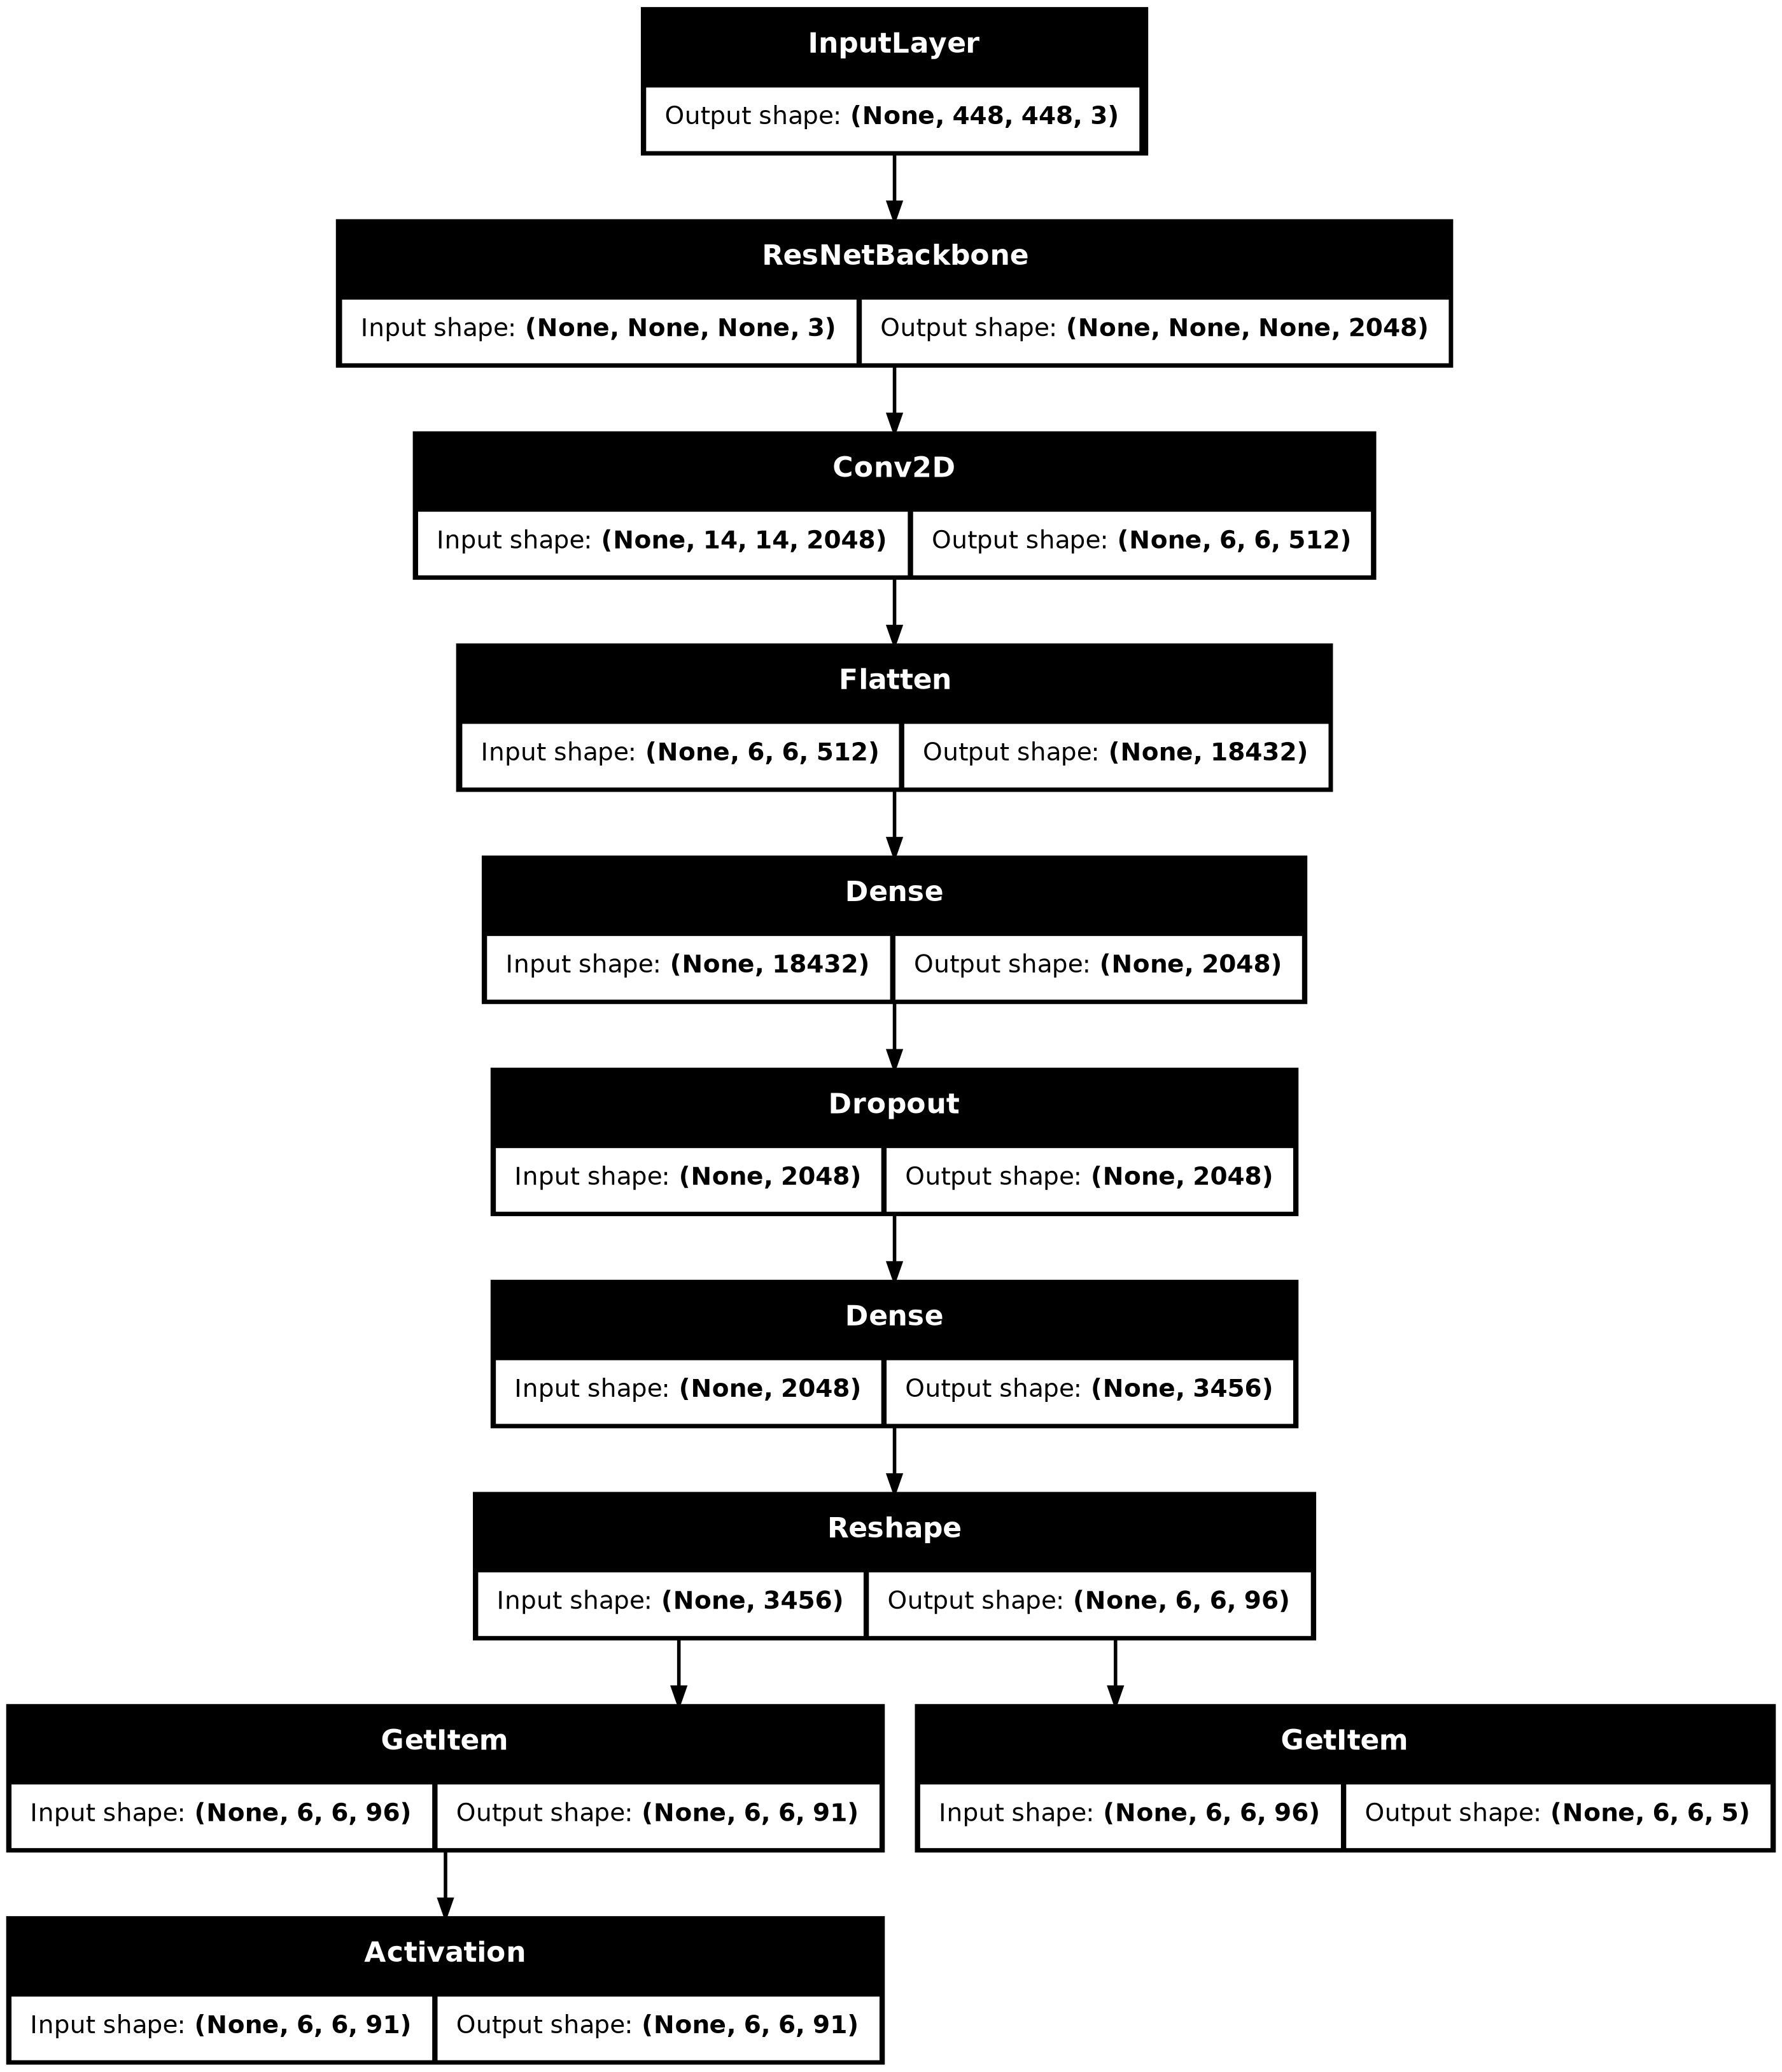

In [ ]:
from keras import layers

grid_size = 6
num_labels = 91  # COCO category IDs, including unused IDs

inputs = keras.Input(shape=(image_size, image_size, 3))

# Extract spatial features using the ResNet backbone
x = backbone(inputs)

# Reduce the spatial dimensions and learn additional features
x = layers.Conv2D(512, (3, 3), strides=(2, 2))(x)
x = layers.Flatten()(x)
x = layers.Dense(2048, activation="relu", kernel_initializer="glorot_normal")(x)
x = layers.Dropout(0.5)(x)

# Predict 5 box-related values and class scores for each grid cell
x = layers.Dense(grid_size * grid_size * (num_labels + 5))(x)
x = layers.Reshape((grid_size, grid_size, num_labels + 5))(x)

# Separate box coordinates and objectness from class probabilities
box_predictions = x[..., :5]
class_predictions = layers.Activation("softmax")(x[..., 5:])

outputs = {"box": box_predictions, "class": class_predictions}
model = keras.Model(inputs, outputs)

model.summary()

# boxplot the model:
import graphviz
keras.utils.plot_model(model, show_shapes=True)

## Prepare trhe training set

### Converting bounding boxes to and from grid coordinates

We will assign each box to the grid cell containing its center. The center is represented as an offset within that cell, while width and height remain normalized relative to the full image. The inverse function converts this representation back to `[x, y, width, height]`.

In [ ]:
def to_grid(box):
    x, y, w, h = box
    cx, cy = (x + w / 2) * grid_size, (y + h / 2) * grid_size
    ix, iy = int(cx), int(cy)
    return (ix, iy), (cx - ix, cy - iy, w, h)

def from_grid(loc, box):
    (xi, yi), (x, y, w, h) = loc, box
    x = (xi + x) / grid_size - w / 2
    y = (yi + y) / grid_size - h / 2
    return (x, y, w, h)

### Preparing grid-based training targets

We will create class and bounding box targets for each grid cell. Class labels are first assigned to all cells overlapped by a box. The cell containing the object's center also receives its box coordinates and an objectness target of 1.

If multiple objects have their centers in the same cell, the last one overwrites the previous box target.

In [ ]:
import numpy as np
import math

class_array = np.zeros((len(metadata), grid_size, grid_size))
box_array = np.zeros((len(metadata), grid_size, grid_size, 5))

for index, sample in enumerate(metadata):
    boxes, labels = sample["boxes"], sample["labels"]
    for box, label in zip(boxes, labels):
        (x, y, w, h) = box
        left, right = math.floor(x * grid_size), math.ceil((x + w) * grid_size)
        bottom, top = math.floor(y * grid_size), math.ceil((y + h) * grid_size)
        class_array[index, bottom:top, left:right] = label

for index, sample in enumerate(metadata):
    boxes, labels = sample["boxes"], sample["labels"]
    for box, label in zip(boxes, labels):
        (xi, yi), (grid_box) = to_grid(box)
        box_array[index, yi, xi] = [*grid_box, 1.0]
        class_array[index, yi, xi] = label

### Visualizing grid labels and bounding boxes

We will color each grid cell according to its class label and draw boxes whose objectness scores meet the selected threshold. First, we will use the training targets to check their encoding.

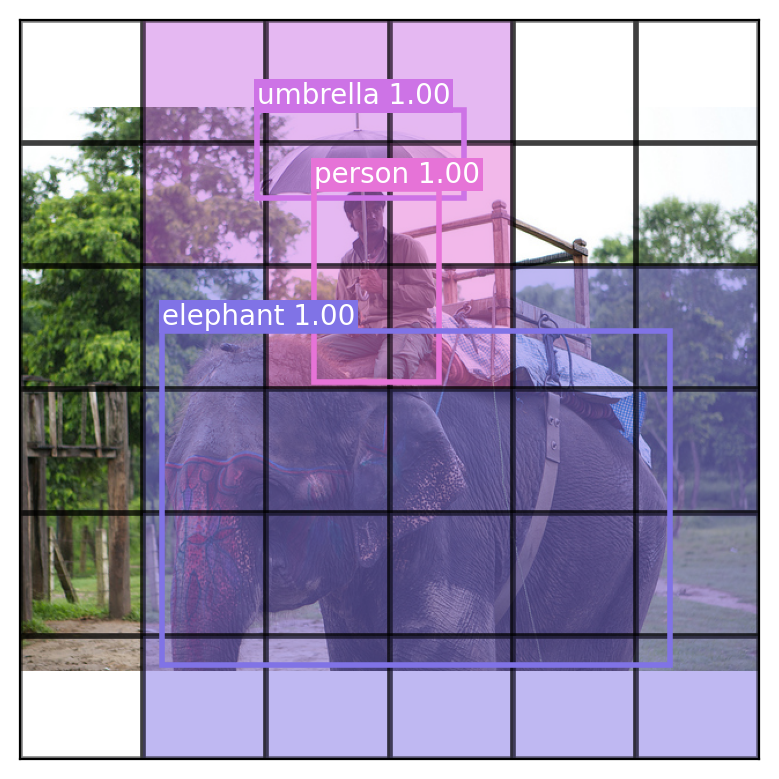

In [ ]:
def draw_prediction(image, boxes, classes, cutoff=None):
    fig, ax = plt.subplots(dpi=200)
    draw_image(ax, image)
    for yi, row in enumerate(classes):
        for xi, label in enumerate(row):
            color = label_to_color(label) if label else "none"
            x, y, w, h = (v / grid_size for v in (xi, yi, 1.0, 1.0))
            r = Rectangle((x, y), w, h, lw=2, ec="black", fc=color, alpha=0.5)
            ax.add_patch(r)
    for yi, row in enumerate(boxes):
        for xi, box in enumerate(row):
            box, confidence = box[:4], box[4]
            if not cutoff or confidence >= cutoff:
                box = from_grid((xi, yi), box)
                label = classes[yi, xi]
                color = label_to_color(label)
                name = keras_hub.utils.coco_id_to_name(label)
                draw_box(ax, box, f"{name} {max(confidence, 0):.2f}", color)
    plt.show()

index = 1789
draw_prediction(metadata[index]["path"], box_array[index], class_array[index], cutoff=1.0)
#draw_prediction(metadata[0]["path"], box_array[0], class_array[0], cutoff=1.0)

### Data loaders

In [ ]:
import tensorflow as tf

def load_image(path):
    x = tf.io.read_file(path)
    x = tf.image.decode_jpeg(x, channels=3)
    return preprocessor(x)

images = tf.data.Dataset.from_tensor_slices([x["path"] for x in metadata])
images = images.map(load_image, num_parallel_calls=8)
labels = {"box": box_array, "class": class_array}
labels = tf.data.Dataset.from_tensor_slices(labels)

dataset = tf.data.Dataset.zip(images, labels).batch(16).prefetch(2)
val_dataset, train_dataset = dataset.take(500), dataset.skip(500)

W0000 00:00:1794914850.654251   17443 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.


## Losses

### Computing intersection over union (IoU)

Intersection over union measures the overlap between two bounding boxes: their intersection area divided by their union area. A value of 1 means a perfect match, while 0 means no overlap.

These helper functions expect boxes in `[center_x, center_y, width, height]` format.

In [ ]:
from keras import ops

def unpack(box):
    return box[..., 0], box[..., 1], box[..., 2], box[..., 3]

def intersection(box1, box2):
    cx1, cy1, w1, h1 = unpack(box1)
    cx2, cy2, w2, h2 = unpack(box2)
    left = ops.maximum(cx1 - w1 / 2, cx2 - w2 / 2)
    bottom = ops.maximum(cy1 - h1 / 2, cy2 - h2 / 2)
    right = ops.minimum(cx1 + w1 / 2, cx2 + w2 / 2)
    top = ops.minimum(cy1 + h1 / 2, cy2 + h2 / 2)
    return ops.maximum(0.0, right - left) * ops.maximum(0.0, top - bottom)

def intersection_over_union(box1, box2):
    cx1, cy1, w1, h1 = unpack(box1)
    cx2, cy2, w2, h2 = unpack(box2)
    intersection_area = intersection(box1, box2)
    a1 = ops.maximum(w1, 0.0) * ops.maximum(h1, 0.0)
    a2 = ops.maximum(w2, 0.0) * ops.maximum(h2, 0.0)
    union_area = a1 + a2 - intersection_area
    return ops.divide_no_nan(intersection_area, union_area)



### Defining the bounding box loss

The loss combines errors in center position, box size, and objectness. Position and size errors apply only to cells containing an object and receive a weight of 5. Empty cells contribute only an objectness error, weighted by 0.5.

For occupied cells, the objectness target is the IoU between the predicted and true boxes. A signed square root allows the size loss to handle negative predictions.

In [ ]:
def signed_sqrt(x):
    return ops.sign(x) * ops.sqrt(ops.absolute(x) + keras.config.epsilon())

def box_loss(true, pred):
    xy_true, wh_true, conf_true = true[..., :2], true[..., 2:4], true[..., 4:]
    xy_pred, wh_pred, conf_pred = pred[..., :2], pred[..., 2:4], pred[..., 4:]
    no_object = conf_true == 0.0
    xy_error = ops.square(xy_true - xy_pred)
    wh_error = ops.square(signed_sqrt(wh_true) - signed_sqrt(wh_pred))
    iou = intersection_over_union(true, pred)
    conf_target = ops.where(no_object, 0.0, ops.expand_dims(iou, -1))
    conf_error = ops.square(conf_target - conf_pred)
    error = ops.concatenate(
        (
            ops.where(no_object, 0.0, xy_error * 5.0),
            ops.where(no_object, 0.0, wh_error * 5.0),
            ops.where(no_object, conf_error * 0.5, conf_error),
        ),
        axis=-1,
    )
    return ops.sum(error, axis=(1, 2, 3))

## Training the YOLO model

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(2e-4),
    loss={"box": box_loss, "class": "sparse_categorical_crossentropy"},
)

# Save the model after each completed epoch
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="coco_yolo_latest.keras",
    save_best_only=False,
    verbose=1,
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=4,
    callbacks=[checkpoint],
)

/home/zuzka/test_tf/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/4


W1117 12:27:53.560381   17540 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


3201/3201 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - box_loss: 3.1299 - class_loss: 2.2142 - loss: 5.3441
Epoch 1: saving model to coco_yolo_latest.keras

Epoch 1: finished saving model to coco_yolo_latest.keras
3201/3201 ━━━━━━━━━━━━━━━━━━━━ 501s 150ms/step - box_loss: 3.1299 - class_loss: 2.2142 - loss: 5.3441 - val_box_loss: 2.1131 - val_class_loss: 1.7969 - val_loss: 3.9100
Epoch 2/4
3200/3201 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - box_loss: 2.1717 - class_loss: 1.6585 - loss: 3.8302
Epoch 2: saving model to coco_yolo_latest.keras

Epoch 2: finished saving model to coco_yolo_latest.keras
3201/3201 ━━━━━━━━━━━━━━━━━━━━ 484s 148ms/step - box_loss: 2.1717 - class_loss: 1.6585 - loss: 3.8302 - val_box_loss: 2.1828 - val_class_loss: 1.4740 - val_loss: 3.6568
Epoch 3/4
3200/3201 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - box_loss: 1.9152 - class_loss: 1.3969 - loss: 3.3121
Epoch 3: saving model to coco_yolo_latest.keras

Epoch 3: finished saving model to coco_yolo_latest.keras
3201/3201 ━━━━━━━━━━━━━━

## Predicting objects in validation images

We will run the model on the first validation batch to obtain bounding boxes, objectness scores, and class probabilities.

In [ ]:
# model = keras.models.load_model("coco_yolo_latest.keras", compile=False)
x, y = next(iter(val_dataset))
preds = model.predict(x)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 661ms/step


In [ ]:
preds = model(x, training=False)
preds = {key: ops.convert_to_numpy(value) for key, value in preds.items()}

In [ ]:
# x, y = next(iter(val_dataset.rebatch(0)))

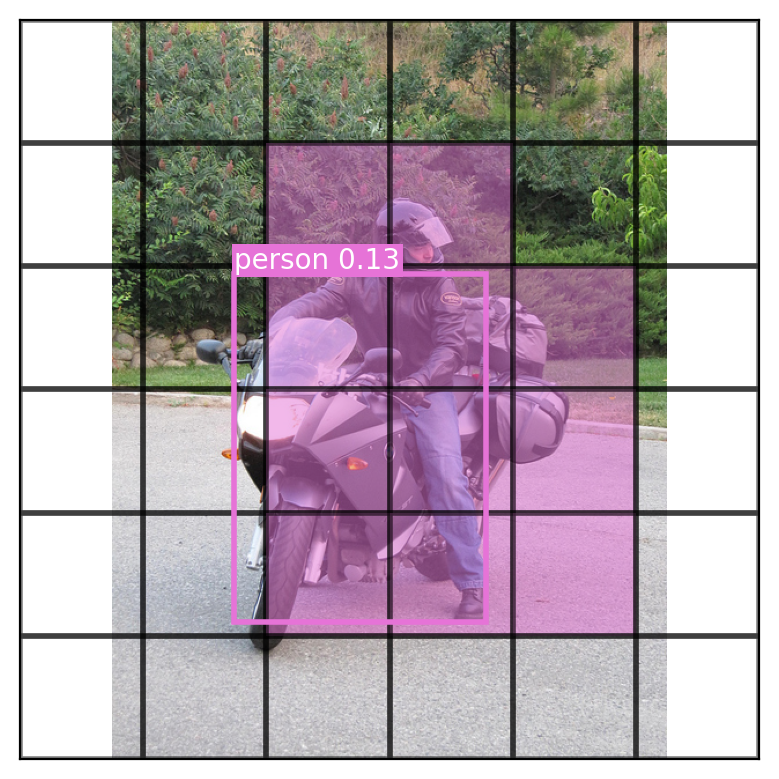

In [ ]:
# Select an image from the first validation batch
i = 1

# Extract predicted boxes and the most probable class for each cell
boxes = preds["box"][i]
classes = np.argmax(preds["class"][i], axis=-1)

# The first validation batch follows the order of metadata
path = metadata[i]["path"]

# Display grid labels and boxes above the objectness threshold
draw_prediction(path, boxes, classes, cutoff=0.1)

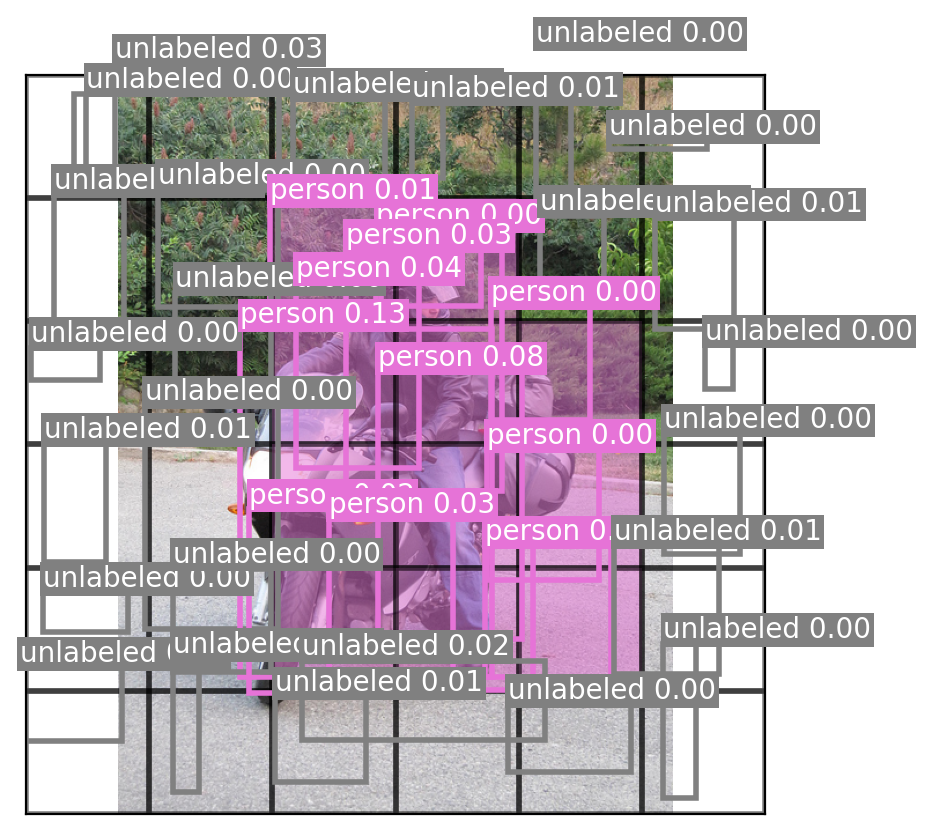

In [ ]:
draw_prediction(path, boxes, classes, cutoff=None)

**Note:** We trained the model for only 4 epochs, so its predictions are still uncertain. For better results, train it for substantially more epochs.

# Using a pretrained RetinaNet detector

RetinaNet is a **one-stage object detector**, similar to YOLO: it predicts bounding boxes and object classes in a single forward pass, without a separate region proposal stage.

It uses a **feature pyramid** to detect objects at different scales and **focal loss** to reduce the influence of easy background examples during training.

Here, we will use a model pretrained on COCO to detect objects without additional training.

### Prepare a test image

In [ ]:
import numpy as np

url = "https://s3.us-east-1.amazonaws.com/book.keras.io/3e/seurat.jpg"
path = keras.utils.get_file(origin=url)
image = np.array([keras.utils.load_img(path)])

### Download the model and make prediction

In [ ]:
detector = keras_hub.models.ObjectDetector.from_preset(
    "retinanet_resnet50_fpn_v2_coco",
    bounding_box_format="rel_xywh",
)
predictions = detector.predict(image)

W1117 13:00:23.871777   17541 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
W1117 13:00:34.415005   17534 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


### Inspect the predictions:

- four different model outputs: bounding boxes, confidences, labels, and the
total number of detections:

In [ ]:
[(k, v.shape) for k, v in predictions.items()]

[('boxes', (1, 100, 4)),
 ('confidence', (1, 100)),
 ('labels', (1, 100)),
 ('num_detections', (1,))]

In [ ]:
predictions["boxes"][0][0]

array([0.02755902, 0.606383  , 0.281068  , 0.16604671], dtype=float32)

### Observe the recognized objects

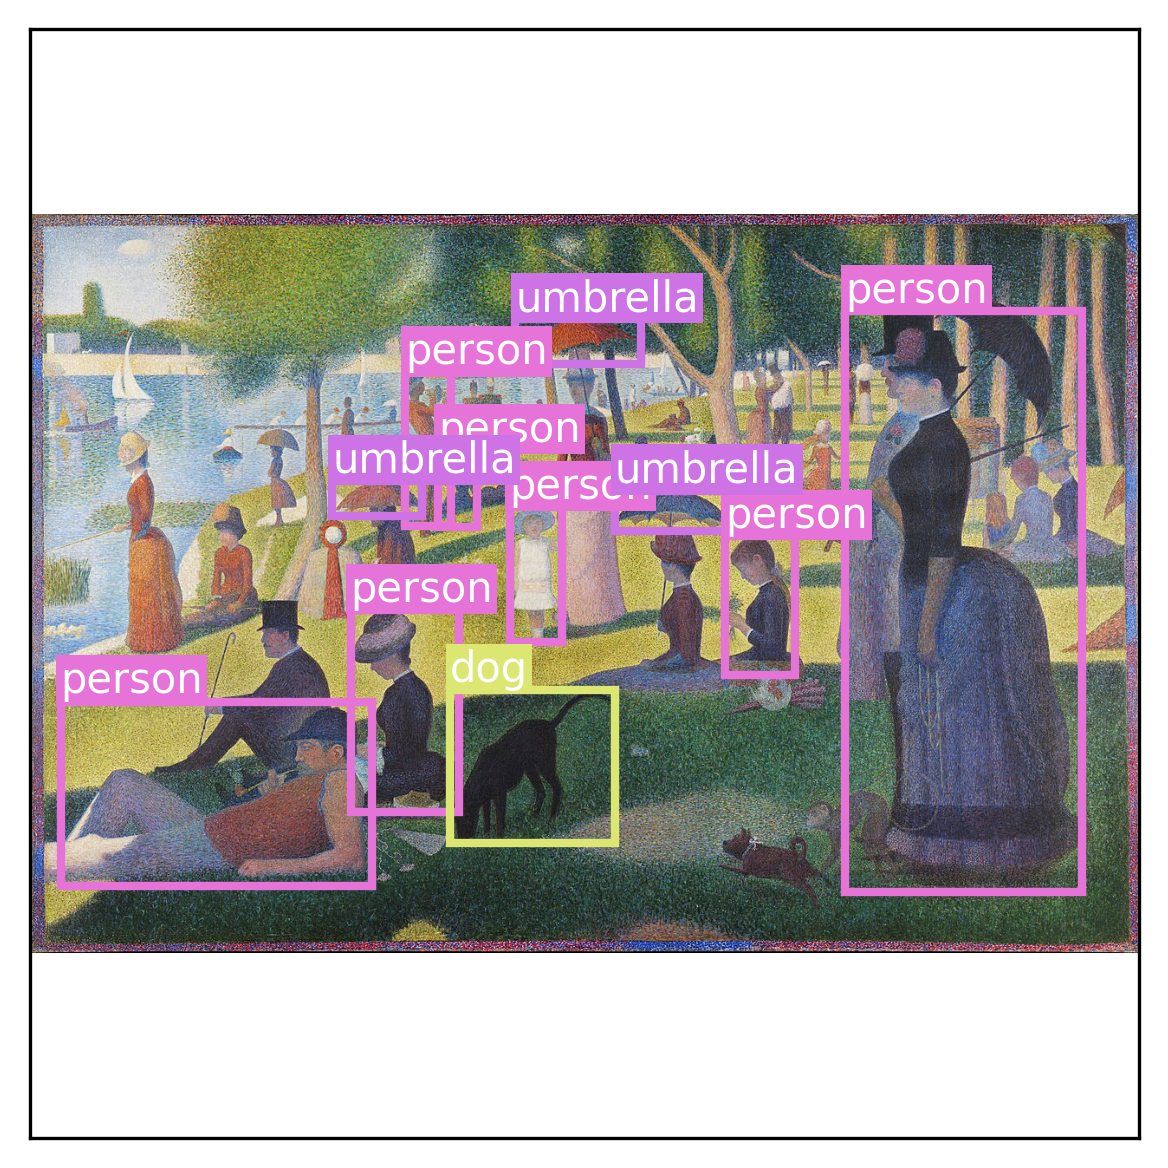

In [ ]:
fig, ax = plt.subplots(dpi=300)
draw_image(ax, path)
num_detections = predictions["num_detections"][0]
for i in range(num_detections):
    box = predictions["boxes"][0][i]
    label = predictions["labels"][0][i]
    label_name = keras_hub.utils.coco_id_to_name(label)
    draw_box(ax, box, label_name, label_to_color(label))
plt.show()

Based on examples from François Chollet (MIT License):
https://github.com/fchollet/deep-learning-with-python-notebooks